# Класифікація зображень грибів: CNN та ViT

Датасет: **FungiTastic-Mini**, фотографії версії `300p`

Клас `0` — їстівний за міткою датасету; клас `1` — отруйний / неїстівний. Отруйні та неїстівні гриби утворюють один клас.

Дослідження: CNN, навчена з нуля, та ViT-B/16 із вагами ImageNet-1K і новим вихідним шаром.

In [ ]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from copy import deepcopy
import hashlib
import json
import random
import time
import platform

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision.models import vit_b_16, ViT_B_16_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

TRAIN_PER_CLASS = 1500
VAL_LIMIT = 1000
TEST_LIMIT = 1500
IMAGE_SIZE = 96
EPOCHS = 8                      # CNN
BATCH_SIZE = 64                 # CNN
VIT_BATCH_SIZE = 8              # виділення ознак при 224 x 224
VIT_HEAD_EPOCHS = 30
VIT_HEAD_BATCH_SIZE = 128
VIT_HEAD_LR = 0.001
THRESHOLD = 0.5

PROJECT = Path.cwd()
if not (PROJECT / 'fungitastic-mini').exists() and (PROJECT.parent / 'fungitastic-mini').exists():
    PROJECT = PROJECT.parent
DATA_ROOT = PROJECT / 'fungitastic-mini' / 'FungiTastic'
META_ROOT = DATA_ROOT / 'metadata' / 'FungiTastic-Mini'
assert META_ROOT.exists(), f'Не знайдено метадані: {META_ROOT}'
OUTPUT = PROJECT / 'work' / 'fungitastic_cnn_vit'
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(PROJECT / 'work' / 'model_cache'))
CLASS_NAMES = ['Їстівний (0)', 'Отруйний / неїстівний (1)']
CNN_NAME = 'Small CNN'
VIT_NAME = 'ViT-B/16 (frozen + linear head)'
MODEL_NAMES = [CNN_NAME, VIT_NAME]
training_seconds = {}
validation_predictions = {}
print('Python:', platform.python_version(), '| sklearn:', sklearn.__version__)
print('torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Пристрій:', DEVICE)
print('Мітки:', dict(enumerate(CLASS_NAMES)))

Python: 3.14.7 | sklearn: 1.9.1
torch: 2.15.0+cpu | torchvision: 0.29.2+cpu
Пристрій: cpu | дані: D:\kma\aislop\fungitastic-mini\FungiTastic
Мітки: {0: 'Їстівний (0)', 1: 'Отруйний / неїстівний (1)'}


## 1. Метадані та поділ

Офіційний часовий поділ: train — до 2022 року, validation — 2022, test — 2023.

На вхід моделей подаємо тільки фото. Епоху обираємо за validation F1.

In [3]:
parts = []
for name, split in [('Train', 'train'), ('Val', 'val'), ('Test', 'test'), ('DNA-Test', 'dna-test')]:
    path = META_ROOT / f'FungiTastic-Mini-{name}.csv'
    frame = pd.read_csv(path, usecols=['filename', 'observationID', 'scientificName',
        'species', 'genus', 'category_id', 'poisonous', 'year'],
        dtype={'observationID': str, 'category_id': str})
    frame['split'] = split
    frame['path'] = frame['filename'].map(lambda f: DATA_ROOT / 'FungiTastic-Mini' / split / '300p' / f)
    parts.append(frame)
metadata = pd.concat(parts, ignore_index=True)
assert metadata['poisonous'].notna().all()
metadata['poisonous'] = metadata['poisonous'].astype(int)
assert set(metadata['poisonous']) == {0, 1}
assert not metadata.duplicated(['split', 'filename']).any()
assert metadata.groupby('observationID')['poisonous'].nunique().max() == 1
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert set(metadata.loc[metadata.split == a, 'observationID']).isdisjoint(
        metadata.loc[metadata.split == b, 'observationID'])
display(pd.crosstab(metadata['split'], metadata['poisonous']).rename(columns={0: 'label_0', 1: 'label_1'}))
display(metadata[['filename', 'species', 'poisonous', 'split']].head())

poisonous,label_0,label_1
split,,
dna-test,567,75
test,8915,1823
train,40999,5843
val,7670,1742


,filename,species,poisonous,split
0,0-3032614317.JPG,Mycena tintinnabulum,0,train
1,1-3032614317.JPG,Mycena tintinnabulum,0,train
2,0-3036761318.JPG,Russula cyanoxantha,0,train
3,1-3036761318.JPG,Russula cyanoxantha,0,train
4,2-3036761318.JPG,Russula cyanoxantha,0,train


## 2. Очищення та підвибірка

Вилучаємо точні копії зі суперечливими назвами/мітками, чорне фото та *Mycena pelianthina* зі спірною міткою. Залишаємо одне фото на спостереження.

Train — 3000 фото (1500 кожного класу), validation — 1000, test — 1500; seed 42. Validation і test зберігають природні пропорції. Обидві моделі використовують ті самі приклади.

Групи копій із суперечностями: 5
Підготовка й хешування, секунд: 7.3


,label_0,label_1
train,1500,1500
val,797,203
test,1222,278


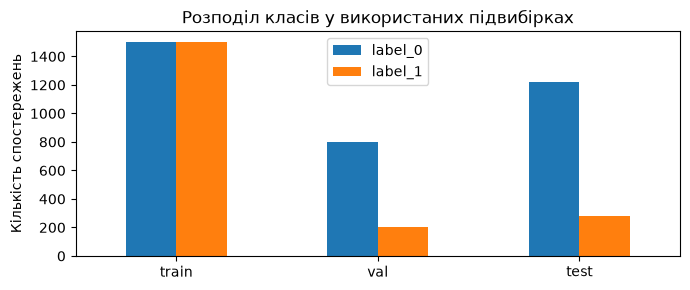

In [4]:
def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

hash_start = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    metadata['sha256'] = list(pool.map(file_hash, metadata['path']))
bad_species_hash = set(metadata.groupby('sha256')['scientificName'].nunique().loc[lambda s: s > 1].index)
bad_label_hash = set(metadata.groupby('sha256')['poisonous'].nunique().loc[lambda s: s > 1].index)
conflicting_hashes = bad_species_hash | bad_label_hash

eligible = metadata.loc[
    metadata['split'].isin(['train', 'val', 'test'])
    & ~metadata['sha256'].isin(conflicting_hashes)
    & metadata['filename'].ne('0-2421822784.JPG')
    & metadata['species'].ne('Mycena pelianthina')
].copy()
eligible['split_order'] = eligible['split'].map({'train': 0, 'val': 1, 'test': 2})
eligible = eligible.sort_values(['split_order', 'filename']).drop_duplicates('sha256')
eligible = eligible.sort_values(['split_order', 'filename']).drop_duplicates('observationID')

train_pool = eligible.loc[eligible.split == 'train']
train_df = pd.concat([g.sample(n=min(TRAIN_PER_CLASS, len(g)), random_state=SEED)
    for _, g in train_pool.groupby('poisonous')]).sample(frac=1, random_state=SEED).reset_index(drop=True)

def limited_split(split, limit):
    frame = eligible.loc[eligible.split == split].copy()
    if limit is not None and len(frame) > limit:
        frame, _ = train_test_split(frame, train_size=limit,
            stratify=frame['poisonous'], random_state=SEED)
    return frame.reset_index(drop=True)

val_df = limited_split('val', VAL_LIMIT)
test_df = limited_split('test', TEST_LIMIT)
selected = {'train': train_df, 'val': val_df, 'test': test_df}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert set(selected[a].sha256).isdisjoint(selected[b].sha256)
    assert set(selected[a].observationID).isdisjoint(selected[b].observationID)
for split, frame in selected.items():
    assert frame.poisonous.nunique() == 2
    frame.drop(columns=['path']).to_csv(OUTPUT / f'{split}_manifest.csv', index=False)
counts = pd.DataFrame({s: f.poisonous.value_counts().sort_index() for s, f in selected.items()}).T
counts.columns = ['label_0', 'label_1']
display(counts)
print('Групи копій із суперечностями:', len(conflicting_hashes))
print('Підготовка й хешування, секунд:', round(time.perf_counter() - hash_start, 1))
counts.plot.bar(rot=0, title='Розподіл класів у використаних підвибірках', figsize=(7, 3))
plt.ylabel('Кількість спостережень'); plt.tight_layout(); plt.show()

train (3000, 96, 96, 3)
val (1000, 96, 96, 3)
test (1500, 96, 96, 3)


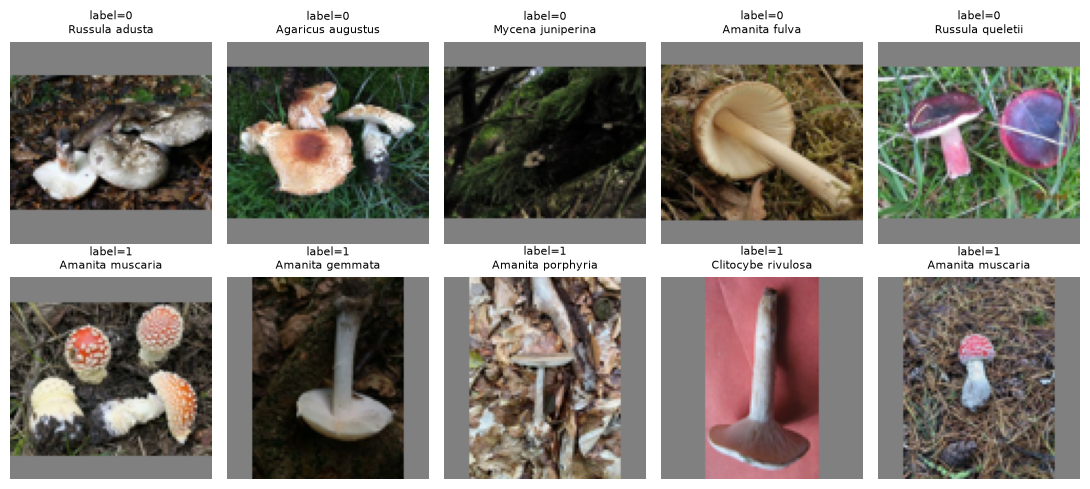

In [ ]:
def load_rgb(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image = ImageOps.pad(image, (IMAGE_SIZE, IMAGE_SIZE), color=(128, 128, 128))
        return np.asarray(image, dtype=np.uint8).copy()

image_arrays, targets = {}, {}
for split, frame in selected.items():
    with ThreadPoolExecutor(max_workers=8) as pool:
        image_arrays[split] = np.stack(list(pool.map(load_rgb, frame['path'])))
    targets[split] = frame['poisonous'].to_numpy(dtype=np.int64)
    print(split, image_arrays[split].shape)

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for label in [0, 1]:
    indices = np.flatnonzero(targets['train'] == label)[:5]
    for ax, index in zip(axes[label], indices):
        ax.imshow(image_arrays['train'][index]); ax.axis('off')
        ax.set_title(f"label={label}\n{train_df.iloc[index]['species']}", fontsize=8)
plt.tight_layout(); plt.show()

## 3. CNN

RGB 96 × 96; три блоки `Conv → ReLU → MaxPool` із 16, 32 і 64 каналами, глобальне усереднення, шари `64 → 32 → 1`, dropout 0.3.
Навчанн: Adam, lr 0.001, batch 64, 8 епох, `BCEWithLogitsLoss`.

Горизонтальне віддзеркалення застосовується лише до train. Поріг — 0.5; епоха обирається за validation F1 класу 1.

Параметрів CNN: 25697
Epoch 1/8: loss=0.6932; validation F1=0.3375
Epoch 2/8: loss=0.6923; validation F1=0.3373
Epoch 3/8: loss=0.6864; validation F1=0.3651
Epoch 4/8: loss=0.6771; validation F1=0.3541
Epoch 5/8: loss=0.6667; validation F1=0.4039
Epoch 6/8: loss=0.6755; validation F1=0.4078
Epoch 7/8: loss=0.6640; validation F1=0.4053
Epoch 8/8: loss=0.6596; validation F1=0.3834
Обрана епоха: 6


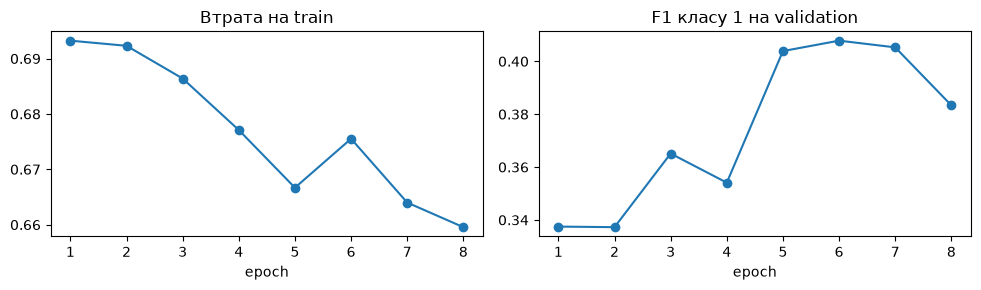

In [6]:
torch.manual_seed(SEED)
class MushroomImages(Dataset):
    def __init__(self, images, labels, augment=False):
        self.images, self.labels, self.augment = images, labels, augment
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        image = torch.from_numpy(self.images[index].copy()).permute(2, 0, 1).float() / 255.0
        if self.augment and torch.rand(()) < 0.5:
            image = torch.flip(image, dims=[2])
        return image, torch.tensor(self.labels[index], dtype=torch.float32)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64, 32),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

loaders = {split: DataLoader(
    MushroomImages(image_arrays[split], targets[split], augment=(split == 'train')),
    batch_size=BATCH_SIZE, shuffle=(split == 'train'), num_workers=0,
    generator=torch.Generator().manual_seed(SEED)) for split in selected}
cnn = SmallCNN().to(DEVICE)
print('Параметрів CNN:', sum(p.numel() for p in cnn.parameters()))
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

def cnn_scores(model, loader):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for images, _ in loader:
            probabilities.append(torch.sigmoid(model(images.to(DEVICE))).cpu().numpy())
    return np.concatenate(probabilities)

history = []
best_validation_f1 = -1.0
best_state = None
start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    cnn.train()
    total_loss = 0.0
    for images, labels in loaders['train']:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = loss_function(cnn(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    val_scores = cnn_scores(cnn, loaders['val'])
    val_pred = (val_scores >= THRESHOLD).astype(int)
    val_f1 = f1_score(targets['val'], val_pred, zero_division=0)
    history.append({'epoch': epoch, 'train_loss': total_loss / len(train_df), 'validation_F1_1': val_f1})
    if val_f1 > best_validation_f1:
        best_validation_f1 = val_f1
        best_state = deepcopy(cnn.state_dict())
        best_epoch = epoch
    print(f'Epoch {epoch}/{EPOCHS}: loss={history[-1]["train_loss"]:.4f}; validation F1={val_f1:.4f}')
training_seconds[CNN_NAME] = time.perf_counter() - start
cnn.load_state_dict(best_state)
validation_predictions[CNN_NAME] = (cnn_scores(cnn, loaders['val']) >= THRESHOLD).astype(int)
torch.save({'state_dict': {k: v.cpu() for k, v in best_state.items()},
    'image_size': IMAGE_SIZE, 'best_epoch': best_epoch, 'seed': SEED}, OUTPUT / 'small_cnn.pt')
print('Обрана епоха:', best_epoch)
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT / 'cnn_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history_df.plot(x='epoch', y='train_loss', marker='o', ax=axes[0], legend=False)
history_df.plot(x='epoch', y='validation_F1_1', marker='o', ax=axes[1], legend=False)
axes[0].set_title('Втрата на train'); axes[1].set_title('F1 класу 1 на validation')
plt.tight_layout(); plt.show()

## 4. ViT-B/16

Ваги — `IMAGENET1K_V1`. Backbone заморожений; навчаємо лінійний шар `768 → 1`. Патчі 16 × 16; resize до 256 по коротшій стороні, центральне обрізання 224 × 224, нормалізація ImageNet.

Ознаки стандартизуємо за train. AdamW, lr 0.001, weight decay 0.01, batch 128, 30 епох; `BCEWithLogitsLoss`, поріг 0.5. Епоху обираємо за validation F1. Ознаки обчислюються пакетами по 8 фото й кешуються.

ViT backbone parameters: 85798656
Trainable backbone parameters: 0
ViT train: 8/3000
ViT train: 200/3000
ViT train: 400/3000
ViT train: 600/3000
ViT train: 800/3000
ViT train: 1000/3000
ViT train: 1200/3000
ViT train: 1400/3000
ViT train: 1600/3000
ViT train: 1800/3000
ViT train: 2000/3000
ViT train: 2200/3000
ViT train: 2400/3000
ViT train: 2600/3000
ViT train: 2800/3000
ViT train: 3000/3000
ViT val: 8/1000
ViT val: 200/1000
ViT val: 400/1000
ViT val: 600/1000
ViT val: 800/1000
ViT val: 1000/1000
Trainable head parameters: 769
ViT head epoch 1: loss=0.5946; val F1=0.5568
ViT head epoch 5: loss=0.4217; val F1=0.6019
ViT head epoch 10: loss=0.3747; val F1=0.6105
ViT head epoch 15: loss=0.3492; val F1=0.6145
ViT head epoch 20: loss=0.3322; val F1=0.6160
ViT head epoch 25: loss=0.3196; val F1=0.6114
ViT head epoch 30: loss=0.3094; val F1=0.6199
Обрана епоха ViT: 29


<ipython-input-7-73a8e0f06efe>:79: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  torch.from_numpy(targets['train']).float()), batch_size=VIT_HEAD_BATCH_SIZE,


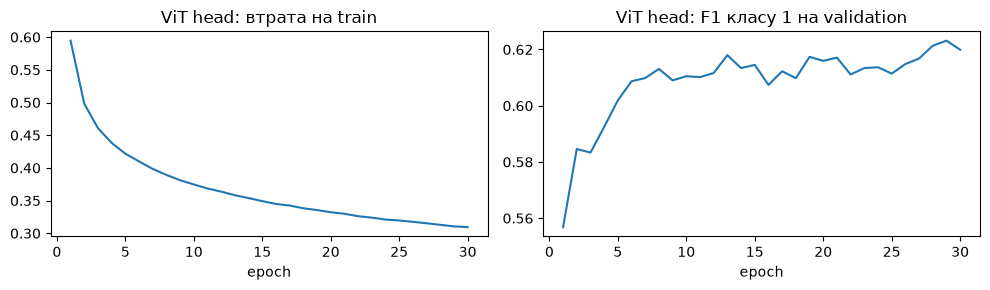

In [7]:
VIT_WEIGHTS = ViT_B_16_Weights.IMAGENET1K_V1
vit_transform = VIT_WEIGHTS.transforms()
vit_backbone = vit_b_16(weights=VIT_WEIGHTS, progress=False)
vit_backbone.heads = nn.Identity()
vit_backbone.requires_grad_(False).eval().to(DEVICE)
print('ViT backbone parameters:', sum(p.numel() for p in vit_backbone.parameters()))
print('Trainable backbone parameters:', sum(p.numel() for p in vit_backbone.parameters() if p.requires_grad))


class ViTPhotos(Dataset):
    def __init__(self, frame):
        self.paths = frame['path'].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            return vit_transform(image)


FEATURE_PROTOCOL = 'torchvision-vit_b_16-IMAGENET1K_V1-resize256-centercrop224-defaultnorm-exif-v1'
feature_seconds = {}
feature_cache_hits = {}


def vit_features(split):
    frame = selected[split]
    digest = hashlib.sha256(FEATURE_PROTOCOL.encode())
    for value in frame['sha256']:
        digest.update(value.encode('ascii'))
    cache_path = OUTPUT / f'vit_features_{split}_{digest.hexdigest()[:20]}.npz'
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as cache:
            values = cache['features'].copy()
            original_seconds = float(cache['extraction_seconds'])
        assert values.shape == (len(frame), 768) and np.isfinite(values).all()
        feature_seconds[split] = original_seconds
        feature_cache_hits[split] = True
        print(f'{split}: кеш ознак {values.shape}')
        return values
    loader = DataLoader(ViTPhotos(frame), batch_size=VIT_BATCH_SIZE,
        shuffle=False, num_workers=0)
    chunks = []
    start = time.perf_counter()
    with torch.inference_mode():
        for batch_index, images in enumerate(loader, start=1):
            chunks.append(vit_backbone(images.to(DEVICE)).cpu().numpy())
            if batch_index == 1 or batch_index % 25 == 0 or batch_index == len(loader):
                done = min(batch_index * VIT_BATCH_SIZE, len(frame))
                progress = {'split': split, 'done': done, 'total': len(frame),
                    'seconds': round(time.perf_counter() - start, 1)}
                (OUTPUT / 'vit_progress.json').write_text(json.dumps(progress), encoding='utf-8')
                print(f'ViT {split}: {done}/{len(frame)}')
    values = np.concatenate(chunks).astype(np.float32)
    assert values.shape == (len(frame), 768) and np.isfinite(values).all()
    elapsed = time.perf_counter() - start
    temp_path = cache_path.with_suffix('.partial.npz')
    np.savez_compressed(temp_path, features=values, extraction_seconds=elapsed)
    temp_path.replace(cache_path)
    feature_seconds[split] = elapsed
    feature_cache_hits[split] = False
    return values


vit_train = vit_features('train')
vit_val = vit_features('val')
feature_mean = torch.from_numpy(vit_train.mean(axis=0))
feature_std = torch.from_numpy(vit_train.std(axis=0)).clamp_min(1e-6)


def normalized_features(values):
    return (torch.from_numpy(values) - feature_mean) / feature_std


torch.manual_seed(SEED)
vit_head = nn.Linear(768, 1).to(DEVICE)
print('Trainable head parameters:', sum(p.numel() for p in vit_head.parameters()))
head_loader = DataLoader(TensorDataset(normalized_features(vit_train),
    torch.from_numpy(targets['train']).float()), batch_size=VIT_HEAD_BATCH_SIZE,
    shuffle=True, generator=torch.Generator().manual_seed(SEED), num_workers=0)
vit_optimizer = torch.optim.AdamW(vit_head.parameters(), lr=VIT_HEAD_LR, weight_decay=0.01)
vit_loss = nn.BCEWithLogitsLoss()


def vit_scores(values):
    vit_head.eval()
    with torch.no_grad():
        return torch.sigmoid(vit_head(normalized_features(values).to(DEVICE)).squeeze(1)).cpu().numpy()


vit_history = []
vit_best_f1 = -1.0
vit_start = time.perf_counter()
for epoch in range(1, VIT_HEAD_EPOCHS + 1):
    vit_head.train()
    total_loss = 0.0
    for vectors, labels in head_loader:
        vectors, labels = vectors.to(DEVICE), labels.to(DEVICE)
        vit_optimizer.zero_grad()
        loss = vit_loss(vit_head(vectors).squeeze(1), labels)
        loss.backward()
        vit_optimizer.step()
        total_loss += loss.item() * len(labels)
    val_f1 = f1_score(targets['val'], vit_scores(vit_val) >= THRESHOLD, zero_division=0)
    vit_history.append({'epoch': epoch, 'train_loss': total_loss / len(train_df),
        'validation_F1_1': val_f1})
    if val_f1 > vit_best_f1:
        vit_best_f1 = val_f1
        vit_best_state = deepcopy(vit_head.state_dict())
        vit_best_epoch = epoch
    if epoch == 1 or epoch % 5 == 0:
        print(f'ViT head epoch {epoch}: loss={vit_history[-1]["train_loss"]:.4f}; val F1={val_f1:.4f}')
vit_head_seconds = time.perf_counter() - vit_start
training_seconds[VIT_NAME] = feature_seconds['train'] + feature_seconds['val'] + vit_head_seconds
vit_head.load_state_dict(vit_best_state)
validation_predictions[VIT_NAME] = (vit_scores(vit_val) >= THRESHOLD).astype(int)
torch.save({'state_dict': {k: v.cpu() for k, v in vit_best_state.items()},
    'feature_mean': feature_mean, 'feature_std': feature_std,
    'architecture': 'vit_b_16', 'weights': 'IMAGENET1K_V1', 'frozen_backbone': True,
    'feature_protocol': FEATURE_PROTOCOL, 'best_epoch': vit_best_epoch,
    'threshold': THRESHOLD, 'seed': SEED}, OUTPUT / 'vit_linear_head.pt')
vit_history_df = pd.DataFrame(vit_history)
vit_history_df.to_csv(OUTPUT / 'vit_history.csv', index=False)
print('Обрана епоха ViT:', vit_best_epoch)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
vit_history_df.plot(x='epoch', y='train_loss', ax=axes[0], legend=False)
vit_history_df.plot(x='epoch', y='validation_F1_1', ax=axes[1], legend=False)
axes[0].set_title('ViT head: втрата на train')
axes[1].set_title('ViT head: F1 класу 1 на validation')
plt.tight_layout(); plt.show()

## 5. Порівняння на test

Порівнюємо зафіксовані після validation моделі. F1, precision і recall стосуються класу 1; balanced accuracy — середній recall двох класів. FN — помилки `1 → 0`, FP — `0 → 1`.

Стратегія більшості передбачає найчастіший клас вихідного train й слугує базовим орієнтиром.

In [ ]:
validation_summary = pd.DataFrame([
    {'model': name, 'validation_F1_1': f1_score(targets['val'], validation_predictions[name], zero_division=0)}
    for name in MODEL_NAMES
]).set_index('model').sort_values('validation_F1_1', ascending=False, kind='stable')
selected_name = validation_summary.index[0]
display(validation_summary)
print('Модель, обрана за validation F1:', selected_name)

test_predictions, test_scores, result_rows = {}, {}, []


def evaluate(name, prediction, scores):
    tn, fp, fn, tp = confusion_matrix(targets['test'], prediction, labels=[0, 1]).ravel()
    return {'model': name, 'accuracy': accuracy_score(targets['test'], prediction),
        'balanced_accuracy': balanced_accuracy_score(targets['test'], prediction),
        'precision_1': precision_score(targets['test'], prediction, zero_division=0),
        'recall_1': recall_score(targets['test'], prediction, zero_division=0),
        'F1_1': f1_score(targets['test'], prediction, zero_division=0),
        'ROC_AUC': roc_auc_score(targets['test'], scores),
        'average_precision': average_precision_score(targets['test'], scores),
        'FN': int(fn), 'FP': int(fp), 'training_and_selection_s': training_seconds.get(name, 0.0)}


test_scores[CNN_NAME] = cnn_scores(cnn, loaders['test'])
vit_test = vit_features('test')
test_scores[VIT_NAME] = vit_scores(vit_test)
for name in MODEL_NAMES:
    scores = test_scores[name]
    test_predictions[name] = (scores >= THRESHOLD).astype(int)
    result_rows.append(evaluate(name, test_predictions[name], scores))
majority = int(train_pool['poisonous'].mode().iloc[0])
baseline = np.full(len(test_df), majority, dtype=int)
result_rows.append(evaluate('Majority baseline', baseline, baseline.astype(float)))
results = pd.DataFrame(result_rows).set_index('model')
display(results.round(4))
results.to_csv(OUTPUT / 'test_comparison.csv')
validation_summary.to_csv(OUTPUT / 'validation_comparison.csv')
pd.DataFrame({'filename': test_df['filename'], 'observationID': test_df['observationID'],
    'actual': targets['test'], 'cnn_score': test_scores[CNN_NAME],
    'vit_score': test_scores[VIT_NAME], 'cnn_prediction': test_predictions[CNN_NAME],
    'vit_prediction': test_predictions[VIT_NAME]}).to_csv(OUTPUT / 'test_predictions.csv', index=False)
(OUTPUT / 'run_config.json').write_text(json.dumps({
    'seed': SEED, 'device': str(DEVICE), 'torch': torch.__version__,
    'torchvision': torchvision.__version__, 'cnn_epochs': EPOCHS,
    'cnn_best_epoch': best_epoch, 'vit_head_epochs': VIT_HEAD_EPOCHS,
    'vit_best_epoch': vit_best_epoch, 'vit_head_lr': VIT_HEAD_LR,
    'threshold': THRESHOLD, 'vit_weights': str(VIT_WEIGHTS),
    'vit_feature_protocol': FEATURE_PROTOCOL, 'feature_seconds': feature_seconds,
    'feature_cache_hits': feature_cache_hits, 'vit_head_seconds': vit_head_seconds,
    'counts': {s: len(f) for s, f in selected.items()},
    'validation_selected_model': selected_name}, indent=2), encoding='utf-8')

Модель, обрана за validation F1: ViT-B/16 (frozen + linear head)
ViT test: 8/1500
ViT test: 200/1500
ViT test: 400/1500
ViT test: 600/1500
ViT test: 800/1500
ViT test: 1000/1500
ViT test: 1200/1500
ViT test: 1400/1500
ViT test: 1500/1500
Out[8]: 772


,validation_F1_1
model,
ViT-B/16 (frozen + linear head),0.623134
Small CNN,0.407821


,accuracy,balanced_accuracy,precision_1,recall_1,F1_1,ROC_AUC,average_precision,FN,FP,training_and_selection_s
model,,,,,,,,,,
Small CNN,0.7887,0.5632,0.3725,0.2050,0.2645,0.5944,0.3062,221,96,55.2223
ViT-B/16 (frozen + linear head),0.7807,0.7917,0.4491,0.8094,0.5777,0.8745,0.6607,53,276,959.4677
Majority baseline,0.8147,0.5000,0.0000,0.0000,0.0000,0.5000,0.1853,278,0,0.0000



Small CNN
                           precision    recall  f1-score   support

             Їстівний (0)     0.8359    0.9214    0.8766      1222
Отруйний / неїстівний (1)     0.3725    0.2050    0.2645       278

                 accuracy                         0.7887      1500
                macro avg     0.6042    0.5632    0.5706      1500
             weighted avg     0.7501    0.7887    0.7632      1500


ViT-B/16 (frozen + linear head)
                           precision    recall  f1-score   support

             Їстівний (0)     0.9469    0.7741    0.8519      1222
Отруйний / неїстівний (1)     0.4491    0.8094    0.5777       278

                 accuracy                         0.7807      1500
                macro avg     0.6980    0.7917    0.7148      1500
             weighted avg     0.8547    0.7807    0.8010      1500



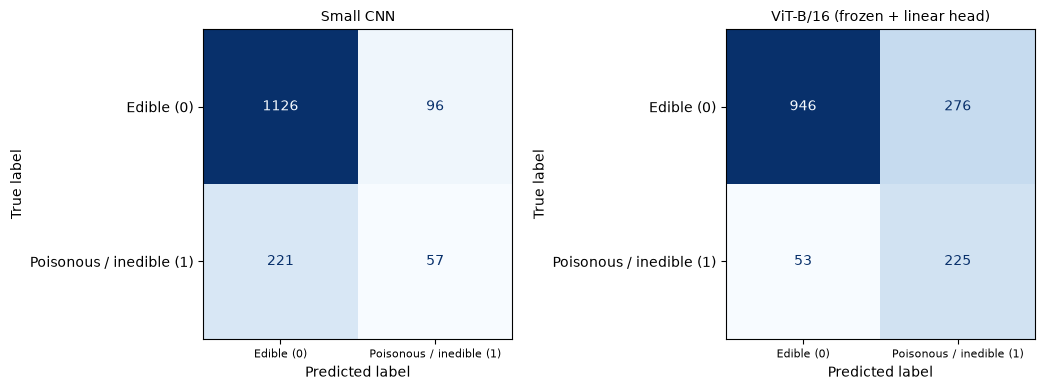

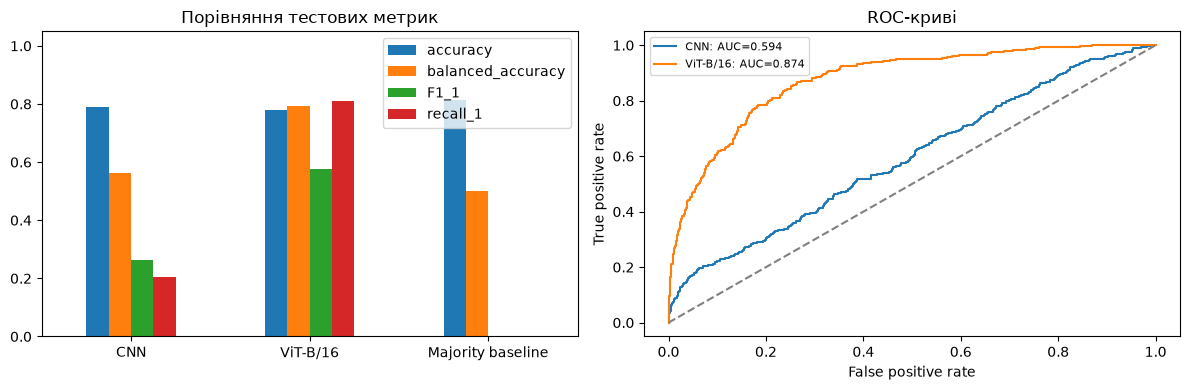

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay.from_predictions(targets['test'], test_predictions[name],
        labels=[0, 1], display_labels=['Edible (0)', 'Poisonous / inedible (1)'],
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_results = results[['accuracy', 'balanced_accuracy', 'F1_1', 'recall_1']].copy()
plot_results.index = ['CNN', 'ViT-B/16', 'Majority baseline']
plot_results.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Порівняння тестових метрик')
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(targets['test'], scores)
    short_name = 'CNN' if name == CNN_NAME else 'ViT-B/16'
    axes[1].plot(fpr, tpr, label=f'{short_name}: AUC={results.loc[name, "ROC_AUC"]:.3f}')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC-криві')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for name in MODEL_NAMES:
    print('\n' + name)
    print(classification_report(targets['test'], test_predictions[name], labels=[0, 1],
        target_names=CLASS_NAMES, digits=4, zero_division=0))

## 6. Висновок

In [ ]:
chosen = results.loc[selected_name]
best_accuracy_name = results.loc[MODEL_NAMES, 'accuracy'].idxmax()
best_f1_name = results.loc[MODEL_NAMES, 'F1_1'].idxmax()
display(Markdown(
    f"За validation F1 класу 1 обрано **{selected_name}**. На test: "
    f"accuracy **{chosen['accuracy']:.2%}**, balanced accuracy **{chosen['balanced_accuracy']:.2%}**, "
    f"F1 класу 1 **{chosen['F1_1']:.4f}**, recall класу 1 **{chosen['recall_1']:.2%}**. "
    f"Пропущено **{int(chosen['FN'])}** прикладів класу 1.\n\n"
    f"Найвища спостережена test accuracy: **{best_accuracy_name}**; "
    f"найвищий test F1 класу 1: **{best_f1_name}** "
    f"Стратегія більшості дає accuracy **{results.loc['Majority baseline', 'accuracy']:.2%}**, "
    "але F1 класу 1 дорівнює нулю.\n\n"
))
print('Результати, прогнози, ваги та списки прикладів:', OUTPUT)

Результати, прогнози, ваги та списки прикладів: D:\kma\aislop\work\fungitastic_cnn_vit


За validation F1 класу 1 обрано **ViT-B/16 (frozen + linear head)**. На test: accuracy **78.07%**, balanced accuracy **79.17%**, F1 класу 1 **0.5777**, recall класу 1 **80.94%**. Пропущено **53** прикладів класу 1.

Найвища спостережена test accuracy: **Small CNN**; найвищий test F1 класу 1: **ViT-B/16 (frozen + linear head)**. Це опис результатів, а не повторний підбір за test.

Стратегія більшості дає accuracy **81.47%**, але F1 класу 1 дорівнює нулю. Тому оцінюємо виявлення класу 1 окремо.

**Інтерпретація:** CNN вивчає ознаки з нуля, а ViT використовує попередньо навчені ознаки ImageNet і новий лінійний вихідний шар. Порівняння характеризує саме ці два підходи, цю підвибірку та обмежений бюджет. Один запуск не встановлює статистично значущої переваги архітектури.